# The Distribution of French Firm Sizes

Chapter 8 of *Probably Overthinking It* is called "The Long Tail of Disaster" because it looks at the distribution of magnitudes for earthquakes, solar flares, asteroid impacts, and stock market crashes, among other kinds of disaster.

In the chapter, I compared two models of these distributions, lognormal and log-t, which are normal and Student t distributions on a log scale. The point of the chapter is this:

* If you look at the tail of these distributions on a linear scale, the lognormal model seems like a good fit.

* But if you look on a log-y scale, it is visibly clear that the lognormal model underestimates the probability of very large disasters -- in some cases by several orders of magnitude.

* The log-t model looks better: it fits the observed distributions well for both moderate and extreme values, which suggests that it's predictions for the largest disasters are more reliable.

[Here you can read the notebook that contains all of the analysis](https://allendowney.github.io/ProbablyOverthinkingIt/longtail.html#the-distribution-of-disaster).

When I was writing the book, I planned to have a chapter on other distributions with similar tail behavior, including the sizes of cities (by population), companies (both by revenue and number of employees)  TODO.. more

I ended up cutting the chapter for a few reasons: 

* It's hard to get good quality datasets that are large enough to show the tail behavior,

* In some of the datasets I explored, the tail behavior is complicated, and

* It's less obvious for these examples that the tail behavior matters.

But I keep an eye out for datasets to test, and I found one recently.
In France, companies file their annual accounts with the commercial courts, and the [Institut National de la Propriété Industrielle](https://data.inpi.fr) (INPI) publishes the non-confidential accounts as open data.
That includes private companies, not just publicly traded ones, and it reports revenue for individual companies -- unbinned -- all the way up to the largest firms in the country.

So let's take a look. To characterize the tail behavior, I'll fit the same models I used in the book, lognormal and log-$t$.
And I'll add two more, log-generalized-normal and a Pareto distribution, which is a common choice for data like this.

TODO: summarize the results

[Click here to run this notebook on Colab](https://colab.research.google.com/github/AllenDowney/ProbablyOverthinkingIt/blob/book/examples/firm_size_france.ipynb).

In [1]:
# Install empiricaldist if we don't already have it

try:
    import empiricaldist
except ImportError:
    !pip install empiricaldist

In [2]:
# download utils.py

from os.path import basename, exists


def download(url):
    filename = basename(url)
    if not exists(filename):
        from urllib.request import urlretrieve

        local, _ = urlretrieve(url, filename)
        print("Downloaded " + local)


download(
    "https://github.com/AllenDowney/ProbablyOverthinkingIt/raw/book/notebooks/utils.py"
)
download(
    "https://github.com/AllenDowney/ProbablyOverthinkingIt/raw/book/examples/tail_models.py"
)

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from empiricaldist import Cdf, TailDist
from utils import decorate, set_pyplot_params, plot_error_bounds

set_pyplot_params()

## Data

The data are from INPI, Registre national des entreprises (RNE), *comptes annuels*, bulk stock file of 2026-03-20, accessed 2026-10-15, and reused under the [RNE reuse licence](https://www.inpi.fr/sites/default/files/Licence%20donn%C3%A9es%20RNE_2024.pdf).
This reuse is not endorsed by INPI.

I made an extract with one row per filing and a few variables: fiscal year, length of the fiscal year, type of accounts, confidentiality status, industry, revenue, total assets, and average number of employees.
The extract does not include company identifiers or names, and the results below are aggregate.
The script that makes the extract is [`extract_inpi.py`](https://github.com/AllenDowney/ProbablyOverthinkingIt/blob/book/examples/extract_inpi.py).

In [4]:
DATA_FILE = "inpi_comptes_annuels.parquet"
download(
    "https://github.com/AllenDowney/ProbablyOverthinkingIt/raw/book/data/" + DATA_FILE
)

raw = pd.read_parquet(DATA_FILE)
raw.shape

(6609323, 8)

The extract includes fiscal years from 2016 through 2025, with about 700,000 filings per year.

In [5]:
raw["year"].value_counts().sort_index().loc[2016:]

year
2016    687214
2017    737109
2018    717488
2019    718877
2020    706642
2021    698484
2022    706767
2023    706614
2024    627813
2025    109449
2026        11
2029         1
Name: count, dtype: Int64

I'll use fiscal year 2023, the most recent year that is complete.

In [6]:
year = 2023
df = raw[raw["year"] == year]
len(df)

706614

There are three types of accounts: complete (`C`), simplified (`S`) for smaller companies, and consolidated (`K`) for groups of companies.
Consolidated accounts include the revenue of subsidiaries that also file their own accounts, so I'll drop them to avoid counting the same revenue twice.

In [7]:
df["type_bilan"].value_counts()

type_bilan
C    551587
S    151420
K      3607
Name: count, dtype: int64

In [8]:
df = df[df["type_bilan"].isin(["C", "S"])]
len(df)

703007

I'll also keep only fiscal years that are 12 months long, so revenue is comparable across companies.

In [9]:
df = df[df["duree_mois"] == 12]
len(df)

648606

## Who is missing

Companies can choose to keep part of their accounts confidential, including their income statement, which is where revenue is reported.
Here's how many filings are public and how many are partly confidential.

In [10]:
df["confidentiality"].value_counts()

confidentiality
Public                                 426863
Partiellement confidentiel             205419
Partiellement confidentiel (RAPCAC)     15621
Publication simplifiee                    703
Name: count, dtype: int64

About a third of filings are partly confidential, so they don't report revenue.
That would not be a problem if confidentiality were unrelated to size, but it isn't -- under French law, only small companies can keep their income statement confidential, and the smallest ("micro") companies can keep their entire accounts confidential.

Confidential filings still report total assets, so we can see how the fraction of confidential filings depends on size.

In [11]:
assets = df[df["total_bilan"] > 0].copy()
assets["log_assets"] = np.log10(assets["total_bilan"].astype(float))
assets["confidential"] = assets["confidentiality"].str.startswith("Partiellement")

In [12]:
bins = np.arange(3, 10.25, 0.25)
groups = pd.cut(assets["log_assets"], bins, labels=bins[:-1] + 0.125)
frac_confidential = assets.groupby(groups, observed=True)["confidential"].mean()
frac_confidential.index = frac_confidential.index.astype(float)

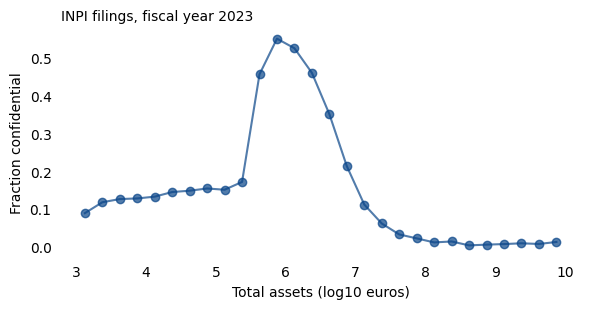

In [13]:
plt.plot(frac_confidential.index, frac_confidential, "o-")

decorate(
    xlabel="Total assets (log10 euros)",
    ylabel="Fraction confidential",
    title=f"INPI filings, fiscal year {year}",
)

Among companies with total assets between about €400,000 and €5 million, a third to a half of filings are partly confidential.
Above €30 million, fewer than 5% are.
The jump near €350,000 is probably the threshold for micro companies: below it, a company that wants confidentiality can withhold its entire accounts, so it doesn't appear here as partly confidential -- or, possibly, at all.

So the companies we can see are a biased sample of companies with revenue below roughly €20 million, and a nearly complete sample above.
Companies that file with zero revenue (many are holding companies) are also excluded, and they are mostly small, too.

To avoid modeling the selection process instead of the distribution of firm sizes, I'll fit the models only to companies above a lower cutoff.
The choice of cutoff is a modeling decision; I'll use €10 million and check later how much the results depend on it.

In [14]:
revenue = df.loc[df["ca"] > 0, "ca"].astype(float)
len(revenue)

335149

In [15]:
cutoff = 1e7

## Distribution of revenue

Here's the CDF of revenue for all companies with positive revenue, with a log-$x$ axis.
The vertical line shows the cutoff.

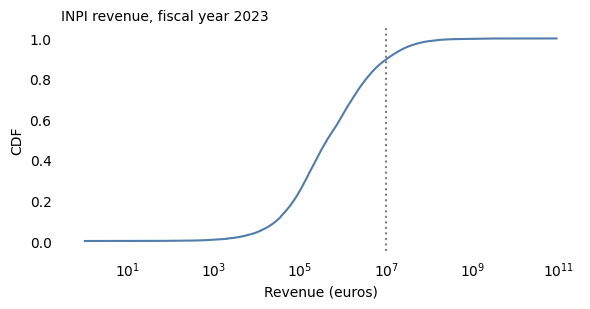

In [16]:
Cdf.from_seq(revenue).plot()
plt.axvline(cutoff, color="gray", ls=":")

decorate(xlabel="Revenue (euros)", ylabel="CDF", xscale="log",
         title=f"INPI revenue, fiscal year {year}")

On a log-$x$ scale, the CDF has the sigmoid shape of a normal distribution, so the lognormal model is a natural candidate.

Now I'll select companies above the cutoff.

In [17]:
selected = revenue[revenue >= cutoff]
n = len(selected)
n

34620

That's about 10% of the companies that report positive revenue.
Here are some summary statistics.

In [18]:
selected.describe()

count    3.462000e+04
mean     9.848275e+07
std      9.561261e+08
min      1.000000e+07
25%      1.498559e+07
50%      2.437491e+07
75%      5.108665e+07
max      9.029100e+10
Name: ca, dtype: float64

In [19]:
ylabel = "Prob >= $x$"

## Log revenue

As in other examples, I'll work with the logarithm of revenue, base 10.
A normal distribution of log revenue is a lognormal distribution of revenue.

In [20]:
mags = np.log10(selected)
mags.describe()

count    34620.000000
mean         7.505843
std          0.446343
min          7.000000
25%          7.175674
50%          7.386943
75%          7.708307
max         10.955644
Name: ca, dtype: float64

In [21]:
tail_log = TailDist.from_seq(mags)

In [22]:
xlabel_log = "Revenue (log10 euros)"

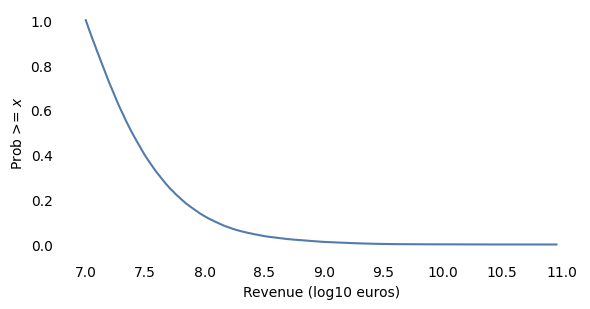

In [23]:
tail_log.plot()

decorate(xlabel=xlabel_log, ylabel=ylabel)

## Fitting truncated models

Because we only use data above the cutoff, each model has to be truncated at the cutoff, too.
The functions that fit the models are in [`tail_models.py`](https://github.com/AllenDowney/ProbablyOverthinkingIt/blob/book/examples/tail_models.py), so the other firm-size examples can use them, too.

* `truncated_tail` evaluates the tail distribution of a SciPy distribution on a grid of quantities, normalized so the probability at the low end of the grid is 1.

* To fit a model, we choose a set of percentiles and find the parameters that minimize the vertical distances between the data and the model at those percentiles. For a model with a shape parameter, like the Student-$t$ distribution, `fit_loc_scale` finds the location and scale for a given value of the shape parameter.

* Then `fit_shape` searches for the value of the shape parameter that best matches the largest values in the data -- specifically, it minimizes the squared differences between the logarithms of the tail probabilities, for probabilities from 1% down to the second-largest value.

* `plot_two` plots the data and a model on a linear-$y$ scale and a log-$y$ scale, side by side. On the log-$y$ scale, the shaded area shows how much variation we would expect due to sampling if the model were correct.

In [24]:
from tail_models import truncated_tail, fit_loc_scale, fit_shape, plot_two, model_errors, YTICKS_LOG

To compare models, I'll compute two kinds of error with `model_errors`:

* The mean absolute difference between the tail distributions of the data and the model, on the linear scale, at 99 percentiles from 1% to 99%. That's mostly sensitive to discrepancies among most of the data.

* The root mean squared difference between the logarithms of the tail probabilities, at 30 points from the 99th percentile to the second-largest value. That's mostly sensitive to discrepancies among the largest companies.

I'll evaluate all models on the same grid, extending a little beyond the largest value.

In [25]:
low, high = tail_log.qs.min(), tail_log.qs.max()
qs = np.linspace(low, high + 0.5, 2000)

In [26]:
results = {}

## Lognormal model

For the lognormal model, I fit a normal distribution to log revenue, truncated at the cutoff.
As in the previous example, I match percentiles from the 10th to the 99th.

In [27]:
from scipy.stats import norm

mu, sigma = fit_loc_scale(norm, tail_log, ps=np.linspace(0.1, 0.99, 20))
mu, sigma

(6.234438157968476, 0.8893719282134149)

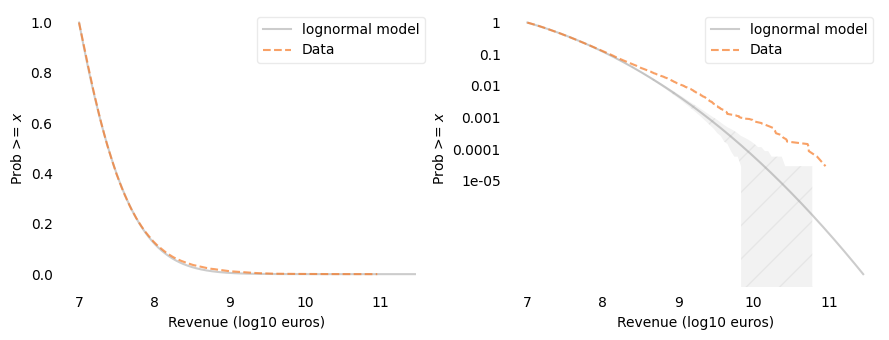

In [28]:
tail_lognormal = truncated_tail(norm, qs, mu, sigma)
plot_two(tail_log, tail_lognormal, n, "lognormal model", xlabel_log)

On the linear-$y$ scale, the lognormal model fits the data well.
On the log-$y$ scale, we can see that it doesn't: above about €300 million, the data are well above the model, and the discrepancy grows to an order of magnitude or more for the largest companies -- far outside the range we would expect from random sampling.
The lognormal model does not fit this distribution.

In [29]:
results["lognormal"] = model_errors(tail_log, tail_lognormal)
results["lognormal"]

(0.0030206012755373147, 0.9123968860608027)

## Log-Student-$t$ model

The Student-$t$ distribution has a parameter, `df`, that controls the thickness of the tails.
With large values of `df`, it is nearly normal; with small values, it has much thicker tails.
A Student-$t$ distribution of log revenue can only have thicker tails than the lognormal model.

In [30]:
from scipy.stats import t as t_dist

df_t = fit_shape(t_dist, tail_log, shape0=10, bounds=(1, 1000))
df_t

12.14698697231906

In [31]:
mu_t, sigma_t = fit_loc_scale(t_dist, tail_log, shape=(df_t,))
mu_t, sigma_t

(6.659525094713831, 0.6968303580660585)

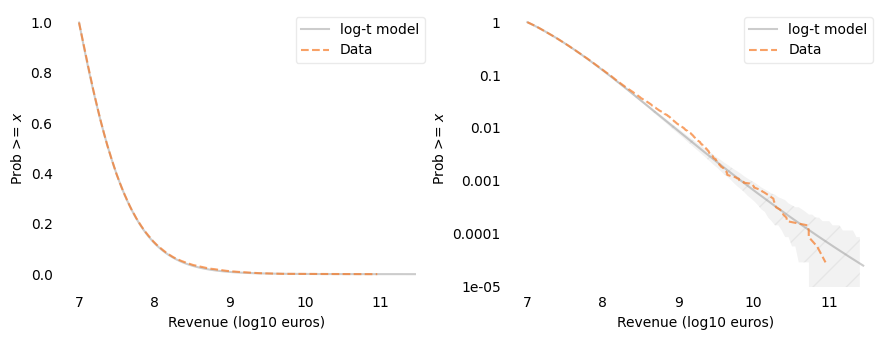

In [32]:
tail_t = truncated_tail(t_dist, qs, df_t, mu_t, sigma_t)
plot_two(tail_log, tail_t, n, "log-t model", xlabel_log)

The log-$t$ model fits the data well on both scales, with `df` about 12.
On the log-$y$ scale, the data are within or close to the range we would expect from random sampling.

In [33]:
results["log-t"] = model_errors(tail_log, tail_t)
results["log-t"]

(0.0017326001874735585, 0.07963289688355323)

## Log-generalized-normal model

The generalized normal distribution has a shape parameter, $\beta$, that can make the tails thicker or thinner than normal: $\beta = 2$ is the normal distribution, $\beta < 2$ has thicker tails, and $\beta > 2$ has thinner tails.
So the lognormal model is a special case of the log-generalized-normal model, and the fitted value of $\beta$ shows which way the data depart from it, if they do.

In [34]:
from scipy.stats import gennorm

beta = fit_shape(gennorm, tail_log, shape0=2, bounds=(0.5, 20))
beta

1.2000364293062293

In [35]:
mu_g, alpha_g = fit_loc_scale(gennorm, tail_log, shape=(beta,))
mu_g, alpha_g

(7.103585900067062, 0.6027924683308655)

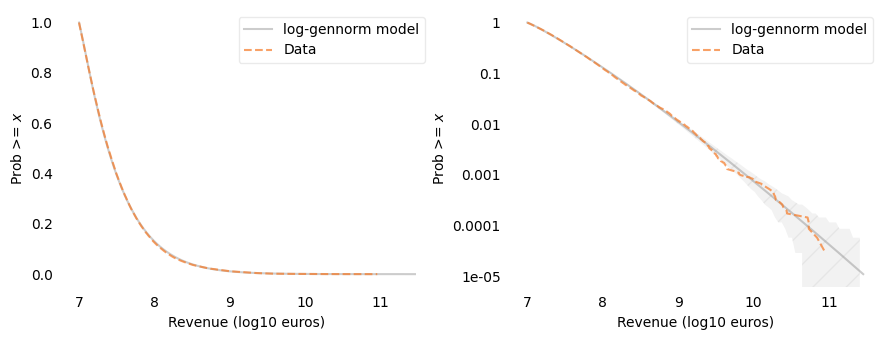

In [36]:
tail_gennorm = truncated_tail(gennorm, qs, beta, mu_g, alpha_g)
plot_two(tail_log, tail_gennorm, n, "log-gennorm model", xlabel_log)

The fitted value of $\beta$ is about 1.2, well below 2, so the departure from the lognormal model is toward thicker tails.
The log-generalized-normal model also fits well on both scales, with the data mostly inside the range we would expect from random sampling.

In [37]:
results["log-gennorm"] = model_errors(tail_log, tail_gennorm)
results["log-gennorm"]

(0.00322010019047377, 0.055884511623134146)

## Pareto model

A Pareto distribution has a tail distribution $P(X \ge x) = (x / x_m)^{-\alpha}$, which is a straight line with slope $-\alpha$ on log-log axes.
With $\alpha = 1$, it is a Zipf distribution.

Truncated at the cutoff, a Pareto distribution has only one parameter, $\alpha$, so it can't bend near the cutoff.
A more flexible version is the Pareto II (or Lomax) distribution, which has a scale parameter, $s$, as well as the exponent:

$$P(X \ge x ~|~ X \ge c) = \left(1 + \frac{x - c}{s}\right)^{-\alpha}$$

where $c$ is the cutoff.
For values much larger than $c + s$, it behaves like a Pareto distribution with exponent $\alpha$; near the cutoff, the scale parameter controls how it bends.

I'll fit it the same way as the other models with a shape parameter: given $\alpha$, `fit_pareto2_scale` finds the scale that matches percentiles of the data, and `fit_pareto2_alpha` searches for the value of $\alpha$ that best matches the largest values in the data, using the same criterion as `fit_shape`.
`pareto2_tail` computes the tail distribution of log revenue under this model.

In [38]:
from tail_models import pareto2_tail, fit_pareto2_scale, fit_pareto2_alpha

log_cutoff = np.log10(cutoff)

In [39]:
alpha = fit_pareto2_alpha(tail_log, log_cutoff)
alpha

1.1328630833740898

In [40]:
log_scale = fit_pareto2_scale(tail_log, alpha, log_cutoff)
log_scale, 10**log_scale

(7.230332796554222, 16995455.023752127)

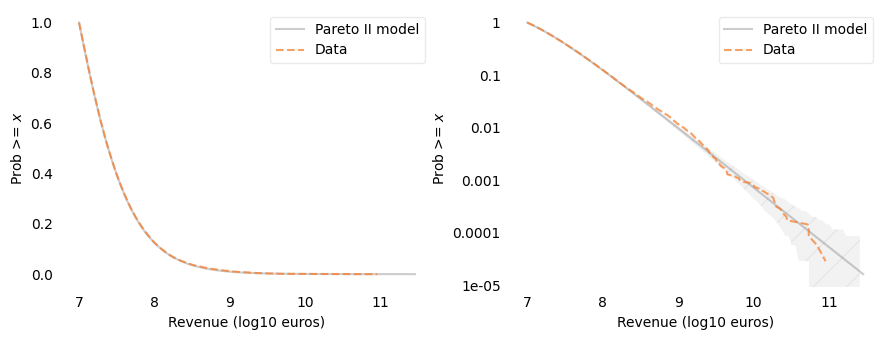

In [41]:
tail_pareto = pareto2_tail(qs, alpha, log_scale, log_cutoff)
plot_two(tail_log, tail_pareto, n, "Pareto II model", xlabel_log)

The fitted exponent is about 1.13, and the scale is about €17 million.
The Pareto II model fits the data well on both scales.
On the log-$y$ scale, the data are mostly within the range we would expect from random sampling; the handful of largest companies are a little below the model, near the edge of that range.

In [42]:
results["Pareto II"] = model_errors(tail_log, tail_pareto)
results["Pareto II"]

(0.0013124275963407996, 0.06039667680172719)

## Comparison

Here are all four models on a log-$y$ scale.

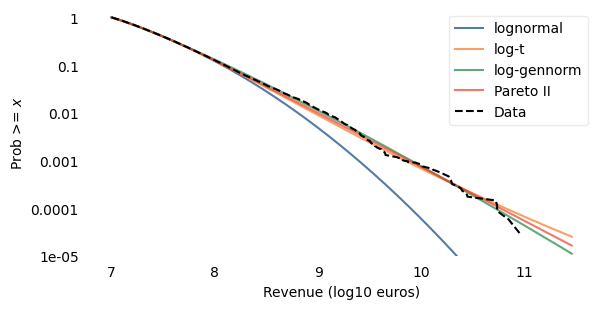

In [43]:
tail_lognormal.plot(label="lognormal")
tail_t.plot(label="log-t")
tail_gennorm.plot(label="log-gennorm")
tail_pareto.plot(label="Pareto II")
tail_log.plot(color="black", ls="--", label="Data")

decorate(xlabel=xlabel_log, ylabel=ylabel, yscale="log", ylim=[1e-5, 1.5])
plt.yticks(YTICKS_LOG, YTICKS_LOG);

And here are the errors.

In [44]:
pd.DataFrame(results, index=["Mean abs error", "RMS log error"]).T.round(4)

,Mean abs error,RMS log error
lognormal,0.0030,0.9124
log-t,0.0017,0.0796
log-gennorm,0.0032,0.0559
Pareto II,0.0013,0.0604


The log-$t$, log-generalized-normal, and Pareto II models all fit well, and their curves are hard to tell apart except beyond the largest companies, where there are no data.
The Pareto II model has the smallest error on the linear scale, and the log-generalized-normal and Pareto II models have the smallest errors on the log scale.
The lognormal model has a small error on the linear scale, but a large error on the log scale.

## Robustness

To see whether these results depend on the year or the cutoff, I'll fit the lognormal, log-generalized-normal, and Pareto II models for each fiscal year from 2016 through 2024, and for several cutoffs.
The following function selects the data.

In [45]:
def select_revenue(raw, year, cutoff):
    """Select log revenue above the cutoff for one fiscal year."""
    df = raw[(raw["year"] == year) & raw["type_bilan"].isin(["C", "S"]) & (raw["duree_mois"] == 12)]
    revenue = df.loc[df["ca"] >= cutoff, "ca"].astype(float)
    return np.log10(revenue)

`fit_models`, in `tail_models.py`, fits the lognormal, log-generalized-normal, and Pareto II models to one dataset and returns the parameters and errors.

In [46]:
from tail_models import fit_models

Here are the results for each year, with the €10 million cutoff.

In [47]:
rows = {y: fit_models(select_revenue(raw, y, cutoff), np.log10(cutoff)) for y in range(2016, 2025)}
by_year = pd.DataFrame(rows).T
by_year.round(3)

,n,beta,alpha,log_scale,rmse_lognormal,rmse_gennorm,rmse_pareto
2016,26218.0,1.138,1.101,7.129,0.396,0.041,0.053
2017,29576.0,1.169,1.121,7.149,0.362,0.046,0.064
2018,30310.0,1.175,1.139,7.163,0.403,0.046,0.064
2019,31851.0,1.177,1.137,7.173,0.540,0.047,0.062
2020,30133.0,1.191,1.156,7.193,0.639,0.044,0.067
2021,31967.0,1.174,1.125,7.199,0.873,0.060,0.064
2022,34212.0,1.204,1.133,7.216,0.749,0.044,0.056
2023,34620.0,1.200,1.133,7.230,0.912,0.056,0.060
2024,32122.0,1.206,1.121,7.241,0.990,0.062,0.071


In every year, the log-generalized-normal and Pareto II models fit well, and the lognormal model does not.
The fitted parameters are consistent from year to year: $\beta$ is between 1.14 and 1.21, and the Pareto exponent is between 1.10 and 1.16.

And here are the results for fiscal year 2023 with several cutoffs.

In [48]:
cutoffs = [1e6, 3e6, 1e7, 3e7, 1e8]
rows = {f"€{c:,.0f}": fit_models(select_revenue(raw, year, c), np.log10(c)) for c in cutoffs}
by_cutoff = pd.DataFrame(rows).T
by_cutoff.round(3)

,n,beta,alpha,log_scale,rmse_lognormal,rmse_gennorm,rmse_pareto
"€1,000,000",125111.0,1.723,1.047,6.489,0.199,0.092,0.110
"€3,000,000",72306.0,1.539,1.091,6.847,0.312,0.097,0.076
"€10,000,000",34620.0,1.200,1.133,7.230,0.912,0.056,0.060
"€30,000,000",14380.0,1.103,1.142,7.574,0.258,0.054,0.061
"€100,000,000",4354.0,NaN,1.147,8.047,inf,inf,0.063


The log-generalized-normal results depend on the cutoff: as the cutoff increases, $\beta$ decreases, from about 1.7 with the €1 million cutoff to about 1.1 with the €30 million cutoff.
With the €100 million cutoff, the lognormal and log-generalized-normal fits don't converge: the best-fitting location moves farther and farther below the cutoff, so the part of the model above the cutoff approaches an exponential distribution of log revenue -- which is a Pareto distribution of revenue.

The Pareto II results hardly depend on the cutoff: the exponent is between 1.05 and 1.15 for all five cutoffs, and the log-scale error is small for all of them.
The scale parameter moves with the cutoff, a little above it in each case, which is where the model bends.

So for every cutoff from €1 million to €100 million, the distribution of revenue above the cutoff is consistent with a Pareto II distribution with exponent a little above 1.
The fit is not as good with the €1 million cutoff, where the selection process has the most effect.


## Employment

The data also include the average number of employees, but only some companies report it.

In [49]:
has_emp = (df["effectif"] > 0).fillna(False)
has_emp.sum(), has_emp.mean()

(70559, 0.10878561098725574)

Larger companies are more likely to report employment, but even among companies with revenue above the cutoff, many don't.

In [50]:
large = df[df["ca"] >= cutoff]
(large["effectif"] > 0).fillna(False).mean()

0.3386481802426343

And some of the values that are reported are clearly wrong.
Here are the number of filings that report at least 10,000 and at least 100,000 employees.

In [51]:
employees = df.loc[has_emp, "effectif"].astype(float)
(employees >= 1e4).sum(), (employees >= 1e5).sum()

(72, 25)

The largest companies in France employ a few hundred thousand people, so most of these can't be right.
Revenue per employee shows the problem: among filings that report 10,000 or more employees, the median is a few hundred euros per employee, compared to about €200,000 for companies with 50 to 1,000 employees.

In [52]:
reported = df[has_emp & (df["ca"] > 0)]
rev_per_emp = reported["ca"].astype(float) / reported["effectif"].astype(float)
emp = reported["effectif"]

rev_per_emp[emp >= 1e4].median(), rev_per_emp[(emp >= 50) & (emp < 1000)].median()

(236.5500764466057, 213295.15128593042)

Errors like these are concentrated among the largest values, which is the part of the distribution we care about most.
So I won't fit models to employment.

## Summary

* Above a cutoff of €10 million, where the selection process has little effect, the lognormal model does not fit the distribution of revenue: the largest companies are far more common than it predicts.

* A Pareto II model with exponent about 1.13 fits the data well on both the linear and log scales, and so do a log-Student-$t$ model and a log-generalized-normal model with $\beta$ about 1.2.

* The Pareto II model is the most consistent: its exponent is between 1.05 and 1.16 for every year from 2016 through 2024 and for every cutoff from €1 million to €100 million. The fitted shape of the log-generalized-normal model depends on the cutoff, and it doesn't fit at all above €100 million.

* Employment data in these filings have errors that are concentrated among the largest values, so I did not model them.

Copyright 2026 Allen B. Downey

Data: INPI -- Registre national des entreprises, comptes annuels (stock of 2026-03-20, accessed 2026-10-15), reused under the RNE reuse licence.

Example related to Chapters 4 and 8 from [Probably Overthinking It](https://allendowney.github.io/ProbablyOverthinkingIt/).

License: [Attribution-NonCommercial-ShareAlike 4.0 International (CC BY-NC-SA 4.0)](https://creativecommons.org/licenses/by-nc-sa/4.0/)